# **Lab 9 - Morphological Operations**

**Course:** ARTI 403 – Image Processing

**Objective:** apply morphological image processing techniques (erosion, dilation, opening and closing) to binary images, and investigate how the shape and the size of the structuring element affect the processed images.

**Image used for the tasks:** `Images/Balls_1_.png` – a binary image of 15 touching balls (black balls on a white background, 1274×1234). The lab demonstration images (`Erosion.jpg`, `Open_Closing.jpg`, `Opening2.jpg`, `BoundaryExtraction.jpg`) are also read from the `Images/` folder.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Images/Erosion.jpg'

# **Erosion Operations**

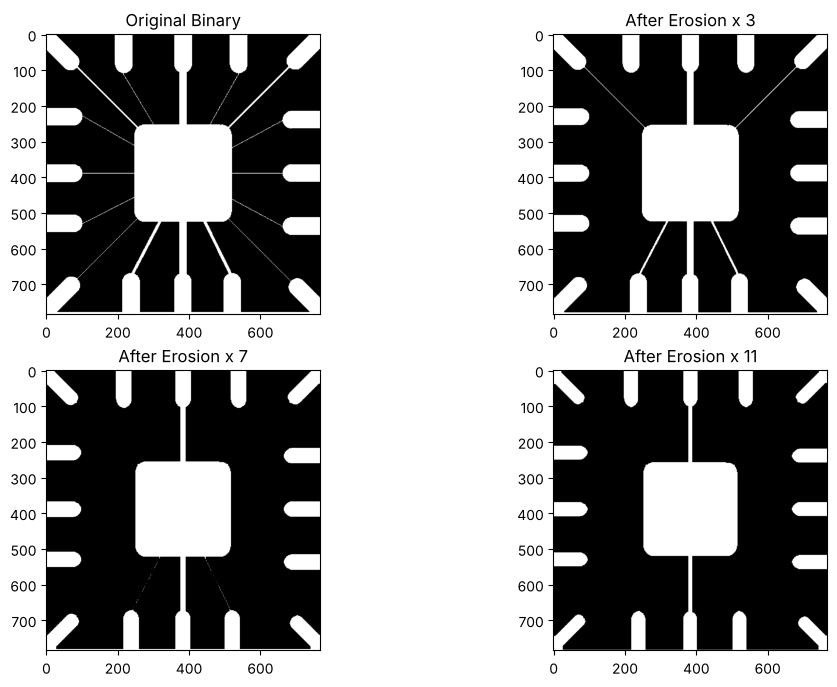

In [2]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)
eroded_img11 = cv2.erode(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Erosion x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Erosion x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Erosion x 11')


plt.show()


# **Dilation Operations**

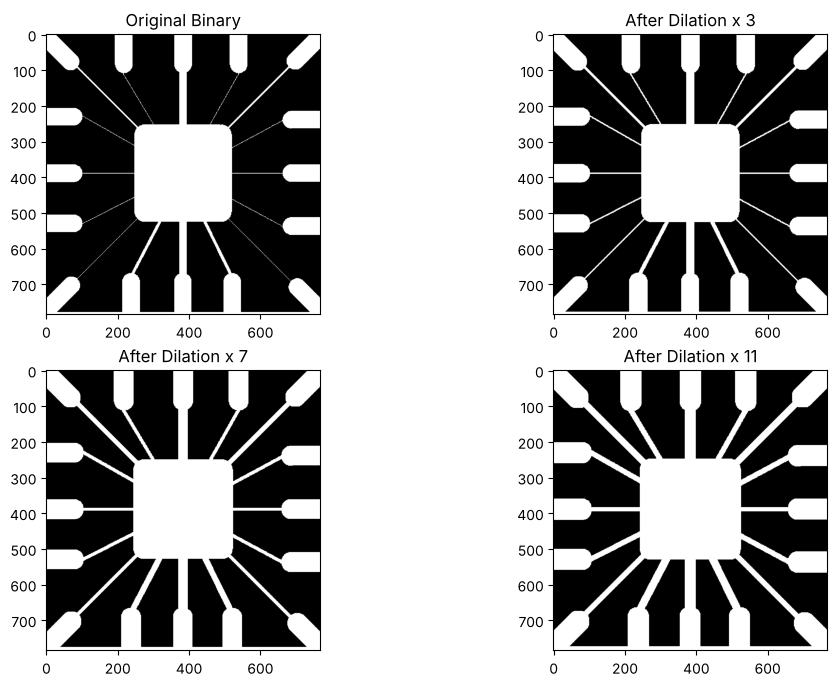

In [3]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.dilate(binary, kernel3, iterations=1)
eroded_img7 = cv2.dilate(binary, kernel7, iterations=1)
eroded_img11 = cv2.dilate(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Dilation x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Dilation x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Dilation x 11')


plt.show()


# **Morphological Open Operations**

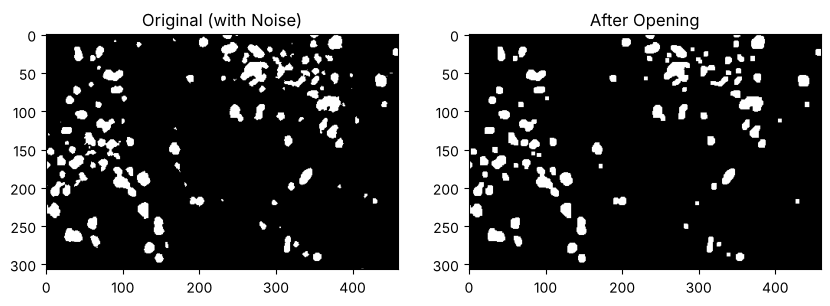

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Images/Open_Closing.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 5x5 square is a good starting point)
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Opening
# This is equivalent to: dilate(erode(binary))
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(opening, 'gray'), plt.title('After Opening')
plt.show()


# **Closing Morphological Operation**

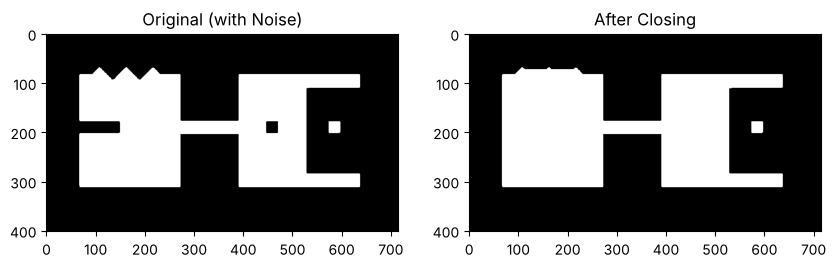

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Images/Opening2.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 45x45 square is a good starting point)
kernel = np.ones((45, 45), np.uint8)

# 3. Apply Opening
# Effectively: cv2.erode(cv2.dilate(binary, kernel), kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(closing, 'gray'), plt.title('After Closing')
plt.show()


# **Boundaries Extractions**

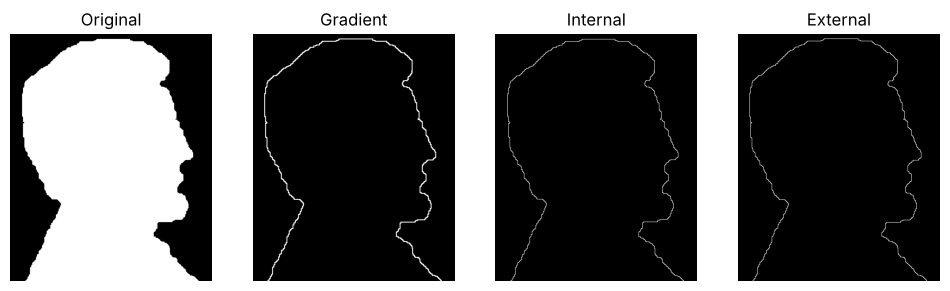

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


imgFile = 'Images/BoundaryExtraction.jpg'
# 1. Load and binarize the image (foreground must be white)
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define a kernel (the size controls boundary thickness)
kernel = np.ones((3, 3), np.uint8)

# 3. Method A: Morphological Gradient (Built-in standard)
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)

# 4. Method B: Internal Boundary (Original - Eroded)
eroded = cv2.erode(binary, kernel)
internal = cv2.subtract(binary, eroded)

# 5. Method C: External Boundary (Dilated - Original)
dilated = cv2.dilate(binary, kernel)
external = cv2.subtract(dilated, binary)

# Visualization
titles = ['Original', 'Gradient', 'Internal', 'External']
images = [binary, gradient, internal, external]

plt.figure(figsize=(12, 4))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# **Task 1: Apply Morphological Operations to a New Image (Balls)**

We use the **Balls** image (`Balls_1_.png`). In the original image the balls are **black** on a **white** background, but morphological operations treat **white (255)** as the foreground. So after Otsu thresholding we **invert** the image (`THRESH_BINARY_INV`) so that the balls become white objects on a black background.

Image shape: (1234, 1274)
Unique values: [  0 255]


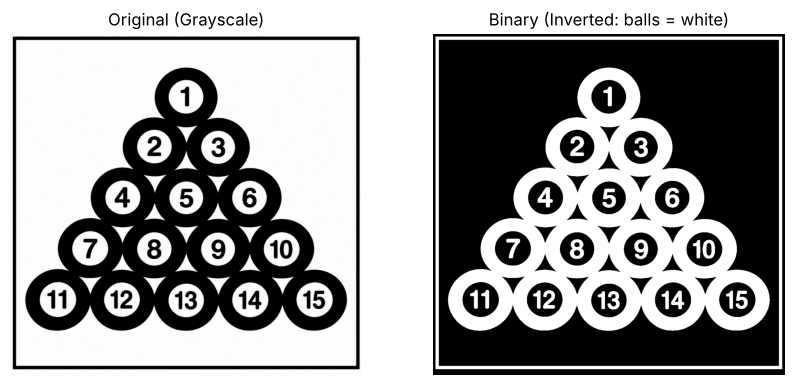

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Images/Balls_1_.png'

# 1. Load image as grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize with Otsu and INVERT so the balls (foreground) are white
_, balls = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

print('Image shape:', balls.shape)
print('Unique values:', np.unique(balls))

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(img, 'gray'), plt.title('Original (Grayscale)'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(balls, 'gray'), plt.title('Binary (Inverted: balls = white)'), plt.axis('off')
plt.show()

## Erosion, Dilation, Opening and Closing

We use a **9x9 square** kernel so the effect is easy to see on this large image.

- **Erosion**: shrinks white regions (removes thin parts and small objects).
- **Dilation**: grows white regions (fills small gaps and holes).
- **Opening** = erosion then dilation (removes small white noise, keeps the main shape size).
- **Closing** = dilation then erosion (fills small black holes, such as the digits inside the balls).

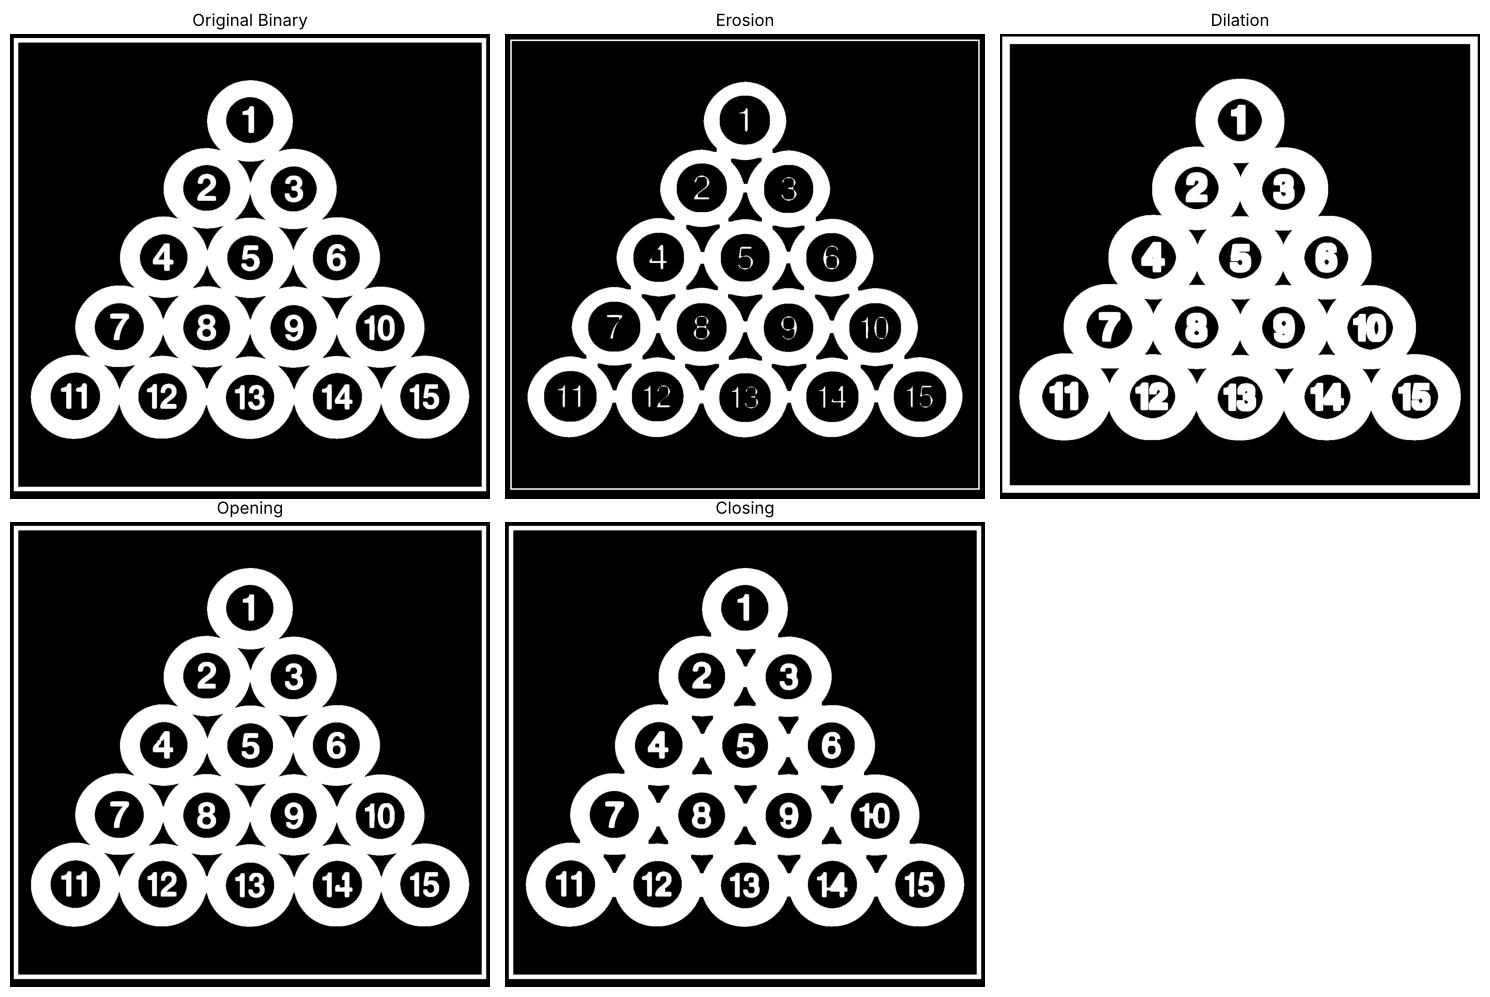

Original Binary  white pixels:   500374
Erosion          white pixels:   363801
Dilation         white pixels:   631178
Opening          white pixels:   499765
Closing          white pixels:   505095


In [8]:
# Kernel
kernel = np.ones((9, 9), np.uint8)

# Operations
erosion  = cv2.erode(balls, kernel, iterations=1)
dilation = cv2.dilate(balls, kernel, iterations=1)
opening  = cv2.morphologyEx(balls, cv2.MORPH_OPEN,  kernel)
closing  = cv2.morphologyEx(balls, cv2.MORPH_CLOSE, kernel)

# Display original + all results
titles = ['Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [balls, erosion, dilation, opening, closing]

plt.figure(figsize=(15, 10))
for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

# Count white pixels to compare the effect numerically
for t, im in zip(titles, images):
    print(f'{t:16s} white pixels: {np.count_nonzero(im):8d}')

### Observations (Task 1)

In the inverted image the **balls' rings are white** and the **inner circles with the numbers are black holes with white digits**.

- **Erosion** makes the white rings thinner, makes the small triangular gaps between the balls larger, and the white digits become very thin (almost disappear). White pixels decrease from 500,374 to 363,801.
- **Dilation** makes the rings thicker, the digits bolder, the inner black circles smaller, and the gaps between the balls smaller. White pixels increase to 631,178.
- **Opening** (erosion then dilation) keeps almost the same size and shape of the balls because they are much bigger than the kernel; it only removes tiny white details (e.g. a small part of the digit 14 is broken). White pixels: 499,765.
- **Closing** (dilation then erosion) keeps the size of the balls but fills the thin black gaps and the narrow black corners between balls, and makes the digits slightly bolder. White pixels: 505,095.

# **Task 2: Experiment with Structuring Elements**

We apply **erosion** and **dilation** using three structuring element **shapes** (square `MORPH_RECT`, cross `MORPH_CROSS`, ellipse `MORPH_ELLIPSE`) and three **sizes** (3x3, 5x5, 7x7).

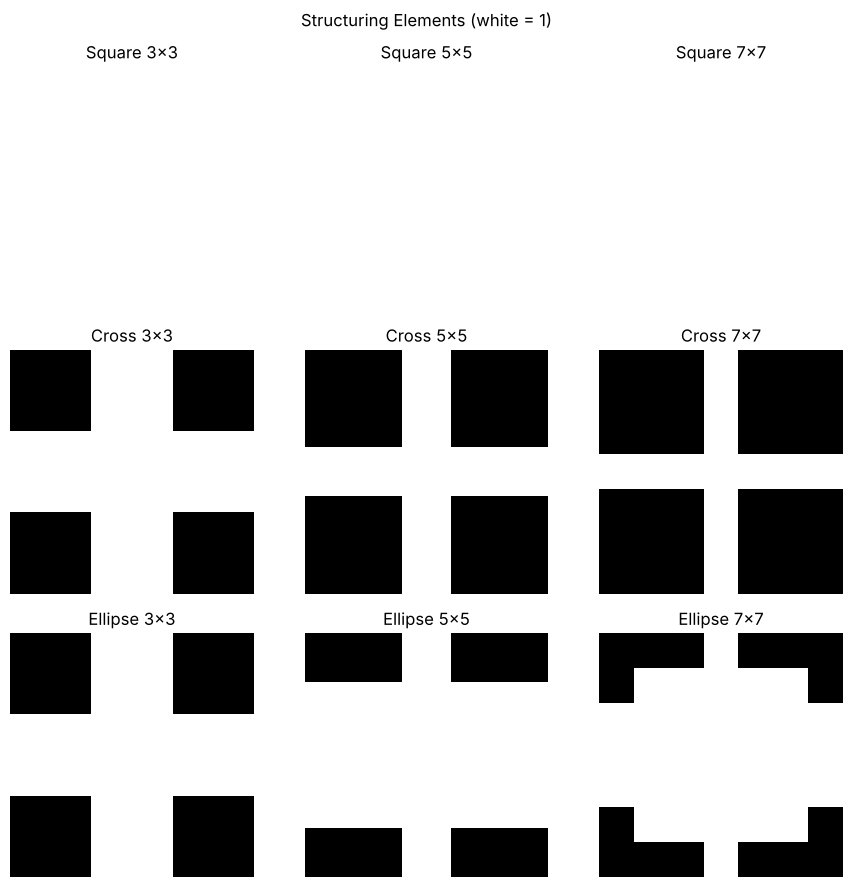

Square 3x3:
[[1 1 1]
 [1 1 1]
 [1 1 1]]
Square 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
Square 7x7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]
Cross 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
Cross 7x7:
[[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]]
Ellipse 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Ellipse 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
Ellipse 7x7:
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]


In [9]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes  = [3, 5, 7]

# Show the structuring elements themselves
plt.figure(figsize=(9, 9))
k = 1
for name, shp in shapes.items():
    for s in sizes:
        se = cv2.getStructuringElement(shp, (s, s))
        plt.subplot(3, 3, k)
        plt.imshow(se, 'gray', vmin=0, vmax=1)
        plt.title(f'{name} {s}x{s}')
        plt.axis('off')
        k += 1
plt.suptitle('Structuring Elements (white = 1)')
plt.tight_layout()
plt.show()

for name, shp in shapes.items():
    for s in sizes:
        print(f'{name} {s}x{s}:')
        print(cv2.getStructuringElement(shp, (s, s)))

## Erosion with different shapes and sizes

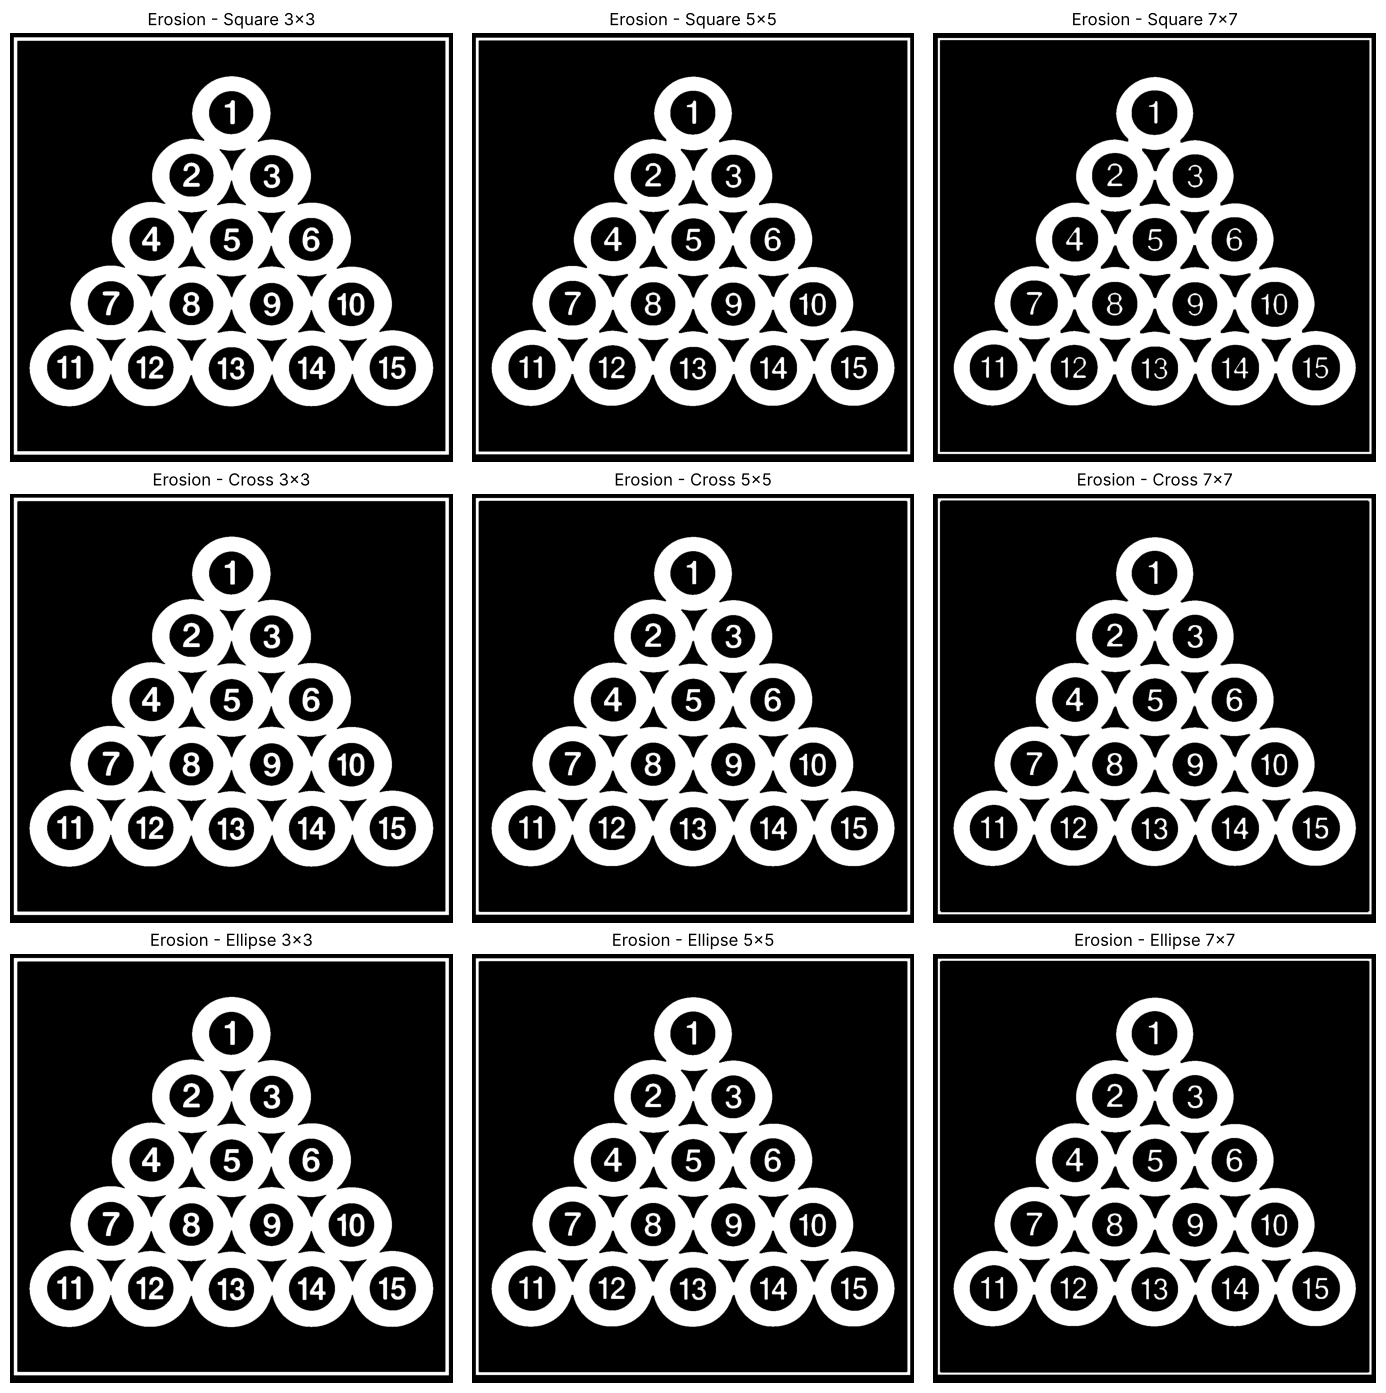

In [10]:
def compare(op, op_name):
    fig, axes = plt.subplots(3, 3, figsize=(14, 14))
    for r, (name, shp) in enumerate(shapes.items()):
        for c, s in enumerate(sizes):
            se = cv2.getStructuringElement(shp, (s, s))
            out = op(balls, se, iterations=1)
            axes[r, c].imshow(out, 'gray')
            axes[r, c].set_title(f'{op_name} - {name} {s}x{s}')
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.show()

compare(cv2.erode, 'Erosion')

## Dilation with different shapes and sizes

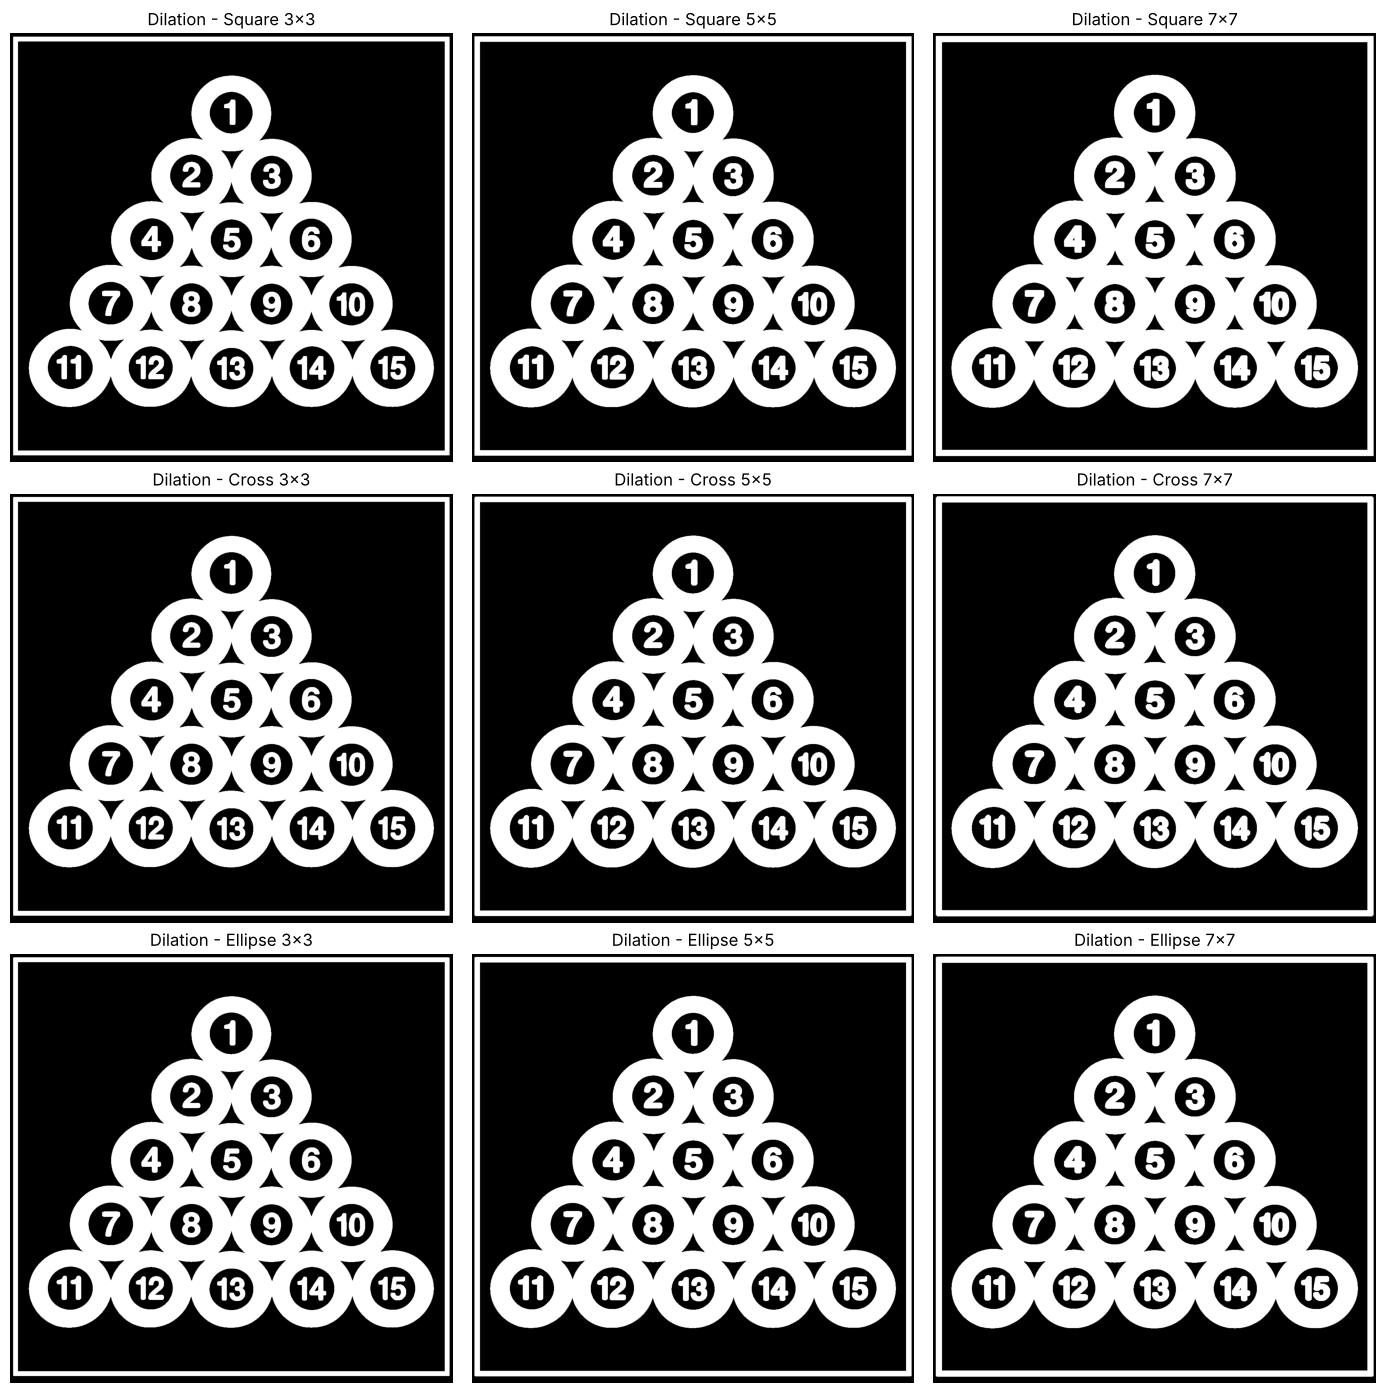

In [11]:
compare(cv2.dilate, 'Dilation')

## Comparison table (number of white pixels)

The original image has a fixed number of white pixels. **Erosion** reduces this number and **dilation** increases it. The bigger the kernel, the bigger the change.

In [12]:
import pandas as pd

rows = []
orig = np.count_nonzero(balls)
for name, shp in shapes.items():
    for s in sizes:
        se = cv2.getStructuringElement(shp, (s, s))
        e = np.count_nonzero(cv2.erode(balls, se))
        d = np.count_nonzero(cv2.dilate(balls, se))
        rows.append({'Shape': name, 'Size': f'{s}x{s}',
                     'Erosion white px': e, 'Erosion change %': round((e - orig) / orig * 100, 2),
                     'Dilation white px': d, 'Dilation change %': round((d - orig) / orig * 100, 2)})

df = pd.DataFrame(rows)
print('Original white pixels:', orig)
df

Original white pixels: 500374


,Shape,Size,Erosion white px,Erosion change %,Dilation white px,Dilation change %
0,Square,3x3,466395,-6.79,534094,6.74
1,Square,5x5,432293,-13.61,567126,13.34
2,Square,7x7,398085,-20.44,599496,19.81
3,Cross,3x3,473108,-5.45,527560,5.43
4,Cross,5x5,445935,-10.88,554380,10.79
5,Cross,7x7,418852,-16.29,580813,16.08
6,Ellipse,3x3,473108,-5.45,527560,5.43
7,Ellipse,5x5,440791,-11.91,559214,11.76
8,Ellipse,7x7,413345,-17.39,585692,17.05


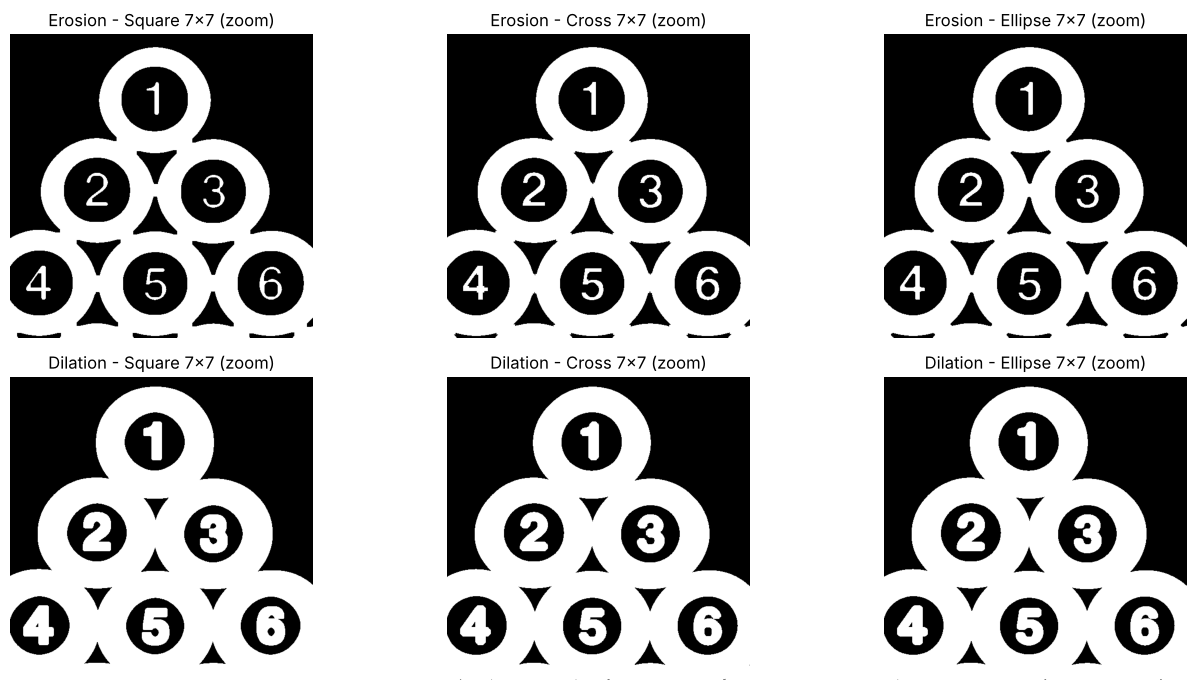

In [13]:
# Side-by-side: effect of SHAPE at the same size (7x7), cropped to the top of the pyramid for clarity
crop = (slice(100, 700), slice(350, 950))
plt.figure(figsize=(14, 7))
k = 1
for op, op_name in [(cv2.erode, 'Erosion'), (cv2.dilate, 'Dilation')]:
    for name, shp in shapes.items():
        se = cv2.getStructuringElement(shp, (7, 7))
        plt.subplot(2, 3, k)
        plt.imshow(op(balls, se)[crop], 'gray')
        plt.title(f'{op_name} - {name} 7x7 (zoom)')
        plt.axis('off')
        k += 1
plt.tight_layout()
plt.show()

### Observations (Task 2)

**Effect of the kernel shape**
- **Square**: strongest effect (it removes/adds the most pixels) and it shapes edges with sharp, square corners.
- **Cross**: weakest effect because it only uses the horizontal and vertical neighbours; diagonal edges are affected less.
- **Ellipse**: in between, and it treats all directions almost equally, so round objects like the balls stay round. Note that the 3x3 ellipse is the same as the 3x3 cross.

**Effect of the kernel size**
- The larger the kernel (3x3 -> 5x5 -> 7x7), the more aggressive the operation: erosion removes more of the objects (the ring gets thinner and the inner details vanish), and dilation grows them more and merges neighbouring balls and fills the inner circles.

**Conclusion:** the shape controls *how* the objects change (direction and smoothness) and the size controls *how much* they change.

# **Conclusion**
- **Erosion** shrinks the white objects and removes thin parts; **dilation** enlarges them and fills small gaps.
- **Opening** (erosion then dilation) removes small white details while keeping the size of the large objects; **closing** (dilation then erosion) fills small black gaps and holes.
- The **shape** of the structuring element controls *how* the objects change: the square has the strongest effect, the cross the weakest, and the ellipse is in between and keeps round objects round.
- The **size** of the structuring element controls *how much* they change: 3×3 → 5×5 → 7×7 gives a stronger effect each time (for example, square erosion removes 6.79%, 13.61% and 20.44% of the white pixels).